# **Tutorial:** Custom YOLO Object Detection with RoboFlow

In this tutorial, you'll learn how to create a custom YOLO object detection model using your own classes and annotations with RoboFlow.

### **Step 1: Install Required Dependencies**

In [1]:
%pip install --upgrade ultralytics
%pip install opencv-python
%pip install roboflow
%pip install matplotlib
%pip install numpy==1.26.4 --force-reinstall

  Using cached ultralytics-8.4.211-py3-none-any.whl.metadata (47 kB)
  Using cached torch-2.15.0-cp314-cp314-win_amd64.whl.metadata (36 kB)
  Using cached torchvision-0.29.2-py3-none-win_amd64.whl.metadata (5.7 kB)
  Using cached polars-2.1.0-py3-none-any.whl.metadata (11 kB)
  Using cached nvidia_ml_py-13.615.71-py3-none-any.whl.metadata (9.7 kB)
  Using cached ultralytics_thop-2.2.5-py3-none-any.whl.metadata (14 kB)
  Using cached ultralytics_platform-0.1.109-py3-none-any.whl.metadata (18 kB)
  Using cached polars_runtime_32-2.1.0-cp311-abi3-win_amd64.whl.metadata (1.5 kB)
  Using cached filelock-4.2.10-py3-none-any.whl.metadata (2.3 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached httpx-0.28.1-py3-none


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached numpy-1.26.4.tar.gz (15.8 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): still running...
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for numpy: filename=numpy-1.26.4-cp314-cp314-win_amd64.whl size=6235783 sha256=55150dbfda5be1d3f41cec317540d5dc7ac7aa72f7ef40303bbf2cac3cea439e
  Stored in directory: c:\users\usuario\appdata\local\pip\cache\wheels\9f\41\2d\41d9edbbdf1331835527392f3da54c7de611dc6ba3ef296215
Succ

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.4.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.1.0; python_version >= "3.13", but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.3.0; python_version >= "3.14", but you have numpy 1.26.4 which is incompatible.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
pandas 3.1.0 requires numpy>=2.3.3; python_version >= "3.14", but you have numpy 1.26.4 which is incompatible.
scipy 1.18.1 requires numpy<2.8,>=2.0.0, but you have numpy 1.26.4 whic

### **Step 2: Import Required Libraries**

In [2]:
import cv2
from roboflow import Roboflow
from ultralytics import YOLO
import matplotlib.pyplot as plt
import numpy as np
import os
from IPython.display import Image, display

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\Usuario\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


### **Step 3: Set Up RoboFlow Account**

1. Go to RoboFlow and create a free account
2. Create a new project and select "Object Detection" as project type
3. Choose "YOLOv26" as the model format

### **Step 4: Upload and Annotate Your Images**

#### Using RoboFlow Web Interface:

1. Click "Upload" to add your images
2. Use the annotation tool to draw bounding boxes around objects
3. Assign the correct class labels to each bounding box
4. Apply preprocessing and augmentation as needed

### **Step 5. Download your Custom your Dataset**

1. In RoboFlow, go to your project dashboard
2. Click "Generate" to create a dataset version
3. Apply any desired augmentations
4. Click "Export" and select "YOLOv**x**" format (**x** the version you are using)
5. Copy the download code

In [6]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="C5yPYe0RTFzikAHeLoDA")
project = rf.workspace("suarezs-workspace").project("llavero-stich")
version = project.version(1)
dataset = version.download("yolo26")    

  Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl (12.7 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4


  You can safely remove it manually.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


loading Roboflow workspace...
loading Roboflow project...


Extracting Dataset Version Zip to LLAVERO-STICH-1 in yolo26:: 100%|██████████| 158/158 [00:00<00:00, 818.71it/s]


In [23]:
from pathlib import Path
from shutil import move
import random
from ultralytics import YOLO

# Esta ruta debe terminar en LLAVERO-STICH-1, NO en \train
DATASET_DIR = Path(
    r"C:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\SEMANA 3\ACTIVIDAD 10\LLAVERO-STICH-1"
)

train_images = DATASET_DIR / "train" / "images"
train_labels = DATASET_DIR / "train" / "labels"
valid_images = DATASET_DIR / "valid" / "images"
valid_labels = DATASET_DIR / "valid" / "labels"

if not train_images.is_dir() or not train_labels.is_dir():
    raise FileNotFoundError(f"No se encuentran train/images y train/labels en {DATASET_DIR}")

# Si aún no hay validación, separar al azar el 20 % de las imágenes
if not valid_images.is_dir() or not any(valid_images.iterdir()):
    pairs = [
        (image, train_labels / f"{image.stem}.txt")
        for image in train_images.iterdir()
        if image.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]

    missing = [str(image) for image, label in pairs if not label.is_file()]
    if missing:
        raise FileNotFoundError(f"Faltan etiquetas para estas imágenes: {missing[:5]}")
    if len(pairs) < 2:
        raise ValueError("Se necesitan al menos dos imágenes para crear entrenamiento y validación.")

    random.Random(42).shuffle(pairs)
    cantidad_validacion = max(1, round(len(pairs) * 0.2))
    valid_images.mkdir(parents=True, exist_ok=True)
    valid_labels.mkdir(parents=True, exist_ok=True)

    for image, label in pairs[:cantidad_validacion]:
        move(str(image), str(valid_images / image.name))
        move(str(label), str(valid_labels / label.name))


In [8]:
from pathlib import Path

root = Path(dataset.location)
print("Carpetas:", [p.name for p in root.iterdir() if p.is_dir()])
print((root / "data.yaml").read_text())

Carpetas: ['train']
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 2
names: ['LLAVE STICH', 'TOTATODO ROSA']

roboflow:
  workspace: suarezs-workspace
  project: llavero-stich
  version: 1
  license: Private
  url: https://app.roboflow.com/suarezs-workspace/llavero-stich/1


### **Step 6: Train Your Custom YOLO Model**

In [24]:

# Crear una configuración con rutas correctas para esta carpeta
data_yaml = DATASET_DIR / "data_entrenamiento.yaml"
data_yaml.write_text(
    f"path: '{DATASET_DIR.as_posix()}'\n"
    "train: train/images\n"
    "val: valid/images\n"
    "nc: 2\n"
    "names: ['LLAVE STICH', 'TOTATODO ROSA']\n",
    encoding="utf-8",
)

print("Configuración:", data_yaml.is_file())
print("Imágenes train:", len(list(train_images.iterdir())))
print("Imágenes valid:", len(list(valid_images.iterdir())))

model = YOLO("yolo26n.pt")
results = model.train(
    data=str(data_yaml),
    epochs=20,
    imgsz=640,
    batch=8,
    project=str(DATASET_DIR.parent / "runs" / "detect"),
    name="custom_yolo_model",
)

Configuración: True
Imágenes train: 62
Imágenes valid: 16
Ultralytics 8.4.211  Python-3.14.8 torch-2.15.0+cpu CPU (11th Gen Intel Core i7-1165G7 @ 2.80GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\SEMANA 3\ACTIVIDAD 10\LLAVERO-STICH-1\data_entrenamiento.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.

### **Step 7: Evaluate Your Model**

In [25]:
# Evaluate model performance
metrics = model.val()  # Validate the model
print(f"mAP50-95: {metrics.box.map}")
print(f"mAP50: {metrics.box.map50}")

# Show some validation results
!yolo task=detect mode=val model=runs/detect/custom_yolo_model/weights/best.pt data={dataset.location}/data.yaml

Ultralytics 8.4.211  Python-3.14.8 torch-2.15.0+cpu CPU (11th Gen Intel Core i7-1165G7 @ 2.80GHz)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 163.2±32.7 MB/s, size: 29.4 KB)
val: Scanning C:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\SEMANA 3\ACTIVIDAD 10\LLAVERO-STICH-1\valid\labels.cache... 16 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 16/16 3.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.6s/it 1.6s
                   all         16         16      0.989          1      0.995      0.844
           LLAVE STICH          4          4          1      0.999      0.995      0.779
         TOTATODO ROSA         12         12      0.978          1      0.995      0.908
Speed: 2.3ms preprocess, 87.2ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to C:\Users\

Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\.venv\Scripts\yolo.exe\__main__.py", line 5, in <module>
    sys.exit(entrypoint())
             ~~~~~~~~~~^^
  File "c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\.venv\Lib\site-packages\ultralytics\cfg\__init__.py", line 1116, in entrypoint
    check_dict_alignment(full_args_dict, {a: ""})
    ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\.venv\Lib\site-packages\ultralytics\cfg\__init__.py", line 694, in check_dict_alignment
    raise SyntaxError(string) from e
SyntaxError: 'DE' is not a valid YOLO argument. 



### **Step 8: Test Your Custom Model on an Image**


image 1/1 C:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\SEMANA 3\ACTIVIDAD 10\1.jpeg: 640x384 1 LLAVE STICH, 1 TOTATODO ROSA, 110.5ms
Speed: 2.6ms preprocess, 110.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 384)


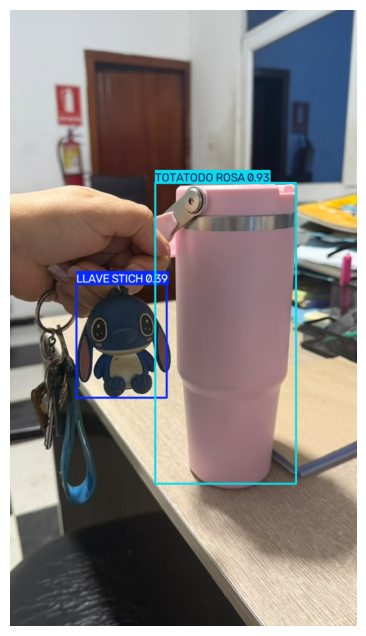

In [26]:
model_path = Path(
    r"C:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\SEMANA 3\ACTIVIDAD 10\runs\detect\custom_yolo_model-12\weights\best.pt"
)
image_path = Path(
    r"C:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\SEMANA 3\ACTIVIDAD 10\1.jpeg"
)

if not model_path.is_file():
    raise FileNotFoundError(f"No se encontró el modelo: {model_path}")
if not image_path.is_file():
    raise FileNotFoundError(f"No se encontró la imagen: {image_path}")

custom_model = YOLO(str(model_path))
results = custom_model.predict(source=str(image_path), conf=0.25)

for result in results:
    imagen_anotada = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 8))
    plt.imshow(imagen_anotada)
    plt.axis("off")
    plt.show()

### **Step 9: Test Your Custom Model on Video**

In [32]:
from pathlib import Path
import cv2
from IPython.display import display, Image
from ultralytics import YOLO

model_path = Path(
    r"C:\Users\Usuario\Documents\2026\BRIGITH\MAESTRIA\FUNDAMENTOS DE INTELIGENCIA ARTIFICIAL\SEMANA 3\ACTIVIDAD 10\runs\detect\custom_yolo_model-12\weights\best.pt"
)

if not model_path.is_file():
    raise FileNotFoundError(f"No se encontró el modelo: {model_path}")

model = YOLO(str(model_path))
camera = cv2.VideoCapture(0, cv2.CAP_DSHOW)

if not camera.isOpened():
    camera.release()
    raise RuntimeError("No se pudo abrir la cámara. Cierra otras aplicaciones que la estén usando.")

try:
    output = None

    while True:
        ok, frame = camera.read()
        if not ok:
            raise RuntimeError("No se pudo leer un fotograma de la cámara.")

        result = model.predict(frame, conf=0.25, imgsz=640, verbose=False)[0]
        success, encoded = cv2.imencode(".jpg", result.plot())

        if not success:
            raise RuntimeError("No se pudo preparar el fotograma para mostrarlo.")

        image = Image(data=encoded.tobytes())

        if output is None:
            output = display(image, display_id=True)
        else:
            output.update(image)

except KeyboardInterrupt:
    print("Prueba detenida.")
finally:
    camera.release()



Prueba detenida.


## **Activity: Create Your Custom Detector**

1. **Create a RoboFlow account** and set up a new project
2. **Upload at least 25 images** of your custom objects (at least 2)
3. **Annotate all images** with bounding boxes and class labels
4. **Train a YOLO model** on your custom dataset
5. **Test your model** on new images and evaluate its performance
6. **Implement real-time detection** with your custom classes

## **Grading Rubric:**

| **Criteria** | **Points** | **Description** |
|-------------|-----------|----------------|
| **1. Dataset Creation** | 4 | Successfully creates and annotates a custom dataset with at least 25 images and multiple classes in RoboFlow. |
| **2. Model Training** | 1 | Properly trains a YOLOv26 model on the custom dataset with appropriate hyperparameters. |
| **3. Model Evaluation** | 1 | Evaluates model performance with appropriate metrics and provides analysis of results. |
| **4. Custom Detection** | 3 | Implements real-time detection with custom classes and displays results correctly. You have to use video from your webcam, no images or saved videos allowed. |
| **5. Documentation** | 1 | Provides clear documentation of the process, including dataset details and model performance. |

**Total: 10 points**

## **Tips for Success:**

- **Quality over quantity**: Well-annotated images are more important than many poorly annotated ones
- **Class balance**: Try to have a similar number of examples for each class
- **Variety**: Include different angles, lighting conditions, and backgrounds
- **Augmentation**: Use RoboFlow's augmentation features to expand your dataset

<p style="text-align: right; font-size:14px; color:gray;">
<b>Prepared by:</b><br>
Manuel Eugenio Morocho-Cayamcela
</p>